# StoManager1 — minimal reproduction: stomatal detection, segmentation, and metric measurement

**Paper:** Jiaxin Wang, Heidi J. Renninger, Qin Ma. *StoManager1: An Enhanced, Automated, and High-throughput Tool to Measure Leaf Stomata and Guard Cell Metrics Using Empirical and Theoretical Algorithms.* Preprint [arXiv:2304.10450v3](https://arxiv.org/abs/2304.10450v3); journal version *Plant Physiology* (2024), DOI [10.1093/plphys/kiae049](https://doi.org/10.1093/plphys/kiae049).

**Author code (pinned):** [`JiaxinWang123/StoManager1`](https://github.com/JiaxinWang123/StoManager1) @ commit `9974130ec64b5a04528177f93a67cb825670e397`.

**What this notebook does (executed partial demonstration):**
1. Installs the author-pinned headless dependencies.
2. Retrieves the pinned author CLI code and the released **YOLOv8x-seg** weights from the author's Zenodo record.
3. Downloads the author's **Toy dataset** from the same Zenodo record and selects a few micrographs.
4. Runs the author's documented headless path: `python cli.py process -m yolov8 -p 465 -c 0.25` then `python cli.py stats -m yolov8`.
5. Shows per-image metric CSVs, the summary statistics workbook, and an input-vs-prediction overlay.

**What is NOT done:** model training, the YOLOv3/Darknet bounding-box path, the Windows GUI, the Populus grouped analysis, and the paper's 11,000-image datasets and biological regressions. A small executed example does **not** verify the paper's dataset-level accuracies.

**実行内容（日本語）:** 著者公開の CLI（YOLOv8x-seg 推論 → 統計出力）を、著者の Zenodo「Toy dataset」の数枚の顕微鏡画像で実行する最小デモです。学習・YOLOv3 経路・GUI・データセット全体の解析は対象外です。

**Execution status:** ✅ executed end-to-end on Google Colab (see final report for runtimes and dates); outputs below are from a fresh Run-all.


## Runtime selection (read first)

- **This demo runs on either CPU or GPU.** The toy example needs only a few inferences, so **CPU is sufficient** (~a few seconds per image). A **T4 GPU** is faster but not required. *Runtime > Change runtime type* — CPU or T4 both work; the notebook detects the hardware in the first code cell.
- Expected total time: ~5–15 min on a fresh runtime (installs ≈ 1–2 min, downloads ≈ 243 MB from Zenodo, inference on 3 images).
- The scientific settings are the author defaults: `pixel_size = 465` px per 0.1 mm, `confidence = 0.25`, `imgsz = 640` (author `config/constants.py` and `cli.py`).

**ランタイム選択（日本語）:** CPU でも T4 GPU でも動作します。 toy 例は数枚の推論のみなので CPU で十分です。全体の目安は 5〜15 分（Zenodo から約 243 MB のダウンロードを含む）。


### 1. Environment check

Prints the Python and preinstalled PyTorch/CUDA status so we can see which hardware this session got **before** installing anything. The scientific path is identical on CPU and GPU; the author's CLI only uses CUDA when the runtime provides it.

**日本語:** 最初にセッションのハードウェア（CPU/GPU の有無）を確認します。著者 CLI は CUDA が使える場合のみ GPU を使用します。


In [ ]:
import sys, platform
import torch

print("Python:", sys.version.split()[0], "|", platform.platform())
print("torch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("This session will use:", DEVICE)


Python: 3.13.16 | Linux-6.6.159+-x86_64-with-glibc2.39
torch: 2.11.0+cpu
CUDA available: False
This session will use: cpu


### 2. Install pinned dependencies

Installs the packages the pinned `requirements.txt` needs for the CLI path. Adaptations, documented:

- **`numpy` is left at the Colab runtime version (NumPy 2.x).** The author's `requirements.txt` pins `numpy<2.0` as a blanket compatibility guard, but NumPy 1.x has no release for this runtime's Python 3.13 (1.26.x supports ≤3.12), and the author code used here (`np.percentile(..., method='midpoint')`, `np.var`, linear algebra on masks) is NumPy-2-compatible. Recorded as a deviation from `requirements.txt`.
- `opencv-python-headless` instead of `opencv-python` — the author README explicitly recommends this for headless servers; Colab has no display.
- `PyQt5`/`qtpy` are **omitted**: they are GUI-only and are not imported by `cli.py`.
- `torch`/`torchvision`, `pandas`, `scipy`, `matplotlib` are preinstalled on Colab and left untouched.

**日本語:** 著者の `requirements.txt` に従い CLI 用の依存をインストールします。ヘッドレス環境用に `opencv-python-headless`（README 記載のサーバー用手順）、GUI 用 PyQt5 は省略します。NumPy 1.x は Python 3.13 に対応しないため、ランタイムの NumPy 2.x を使用します（著者コードは互換であり、報告書に記載の逸脱）。


In [ ]:
%pip install -q "ultralytics>=8.0.0,<9.0.0" "shapely<=2.1" "opencv-python-headless>=4.8,<5.0" "openpyxl>=3.1"
print("install finished")


install finished


### 3. Verify the installed stack and device

Confirms the import graph of the author's CLI path (`ultralytics`, `cv2`, `shapely`, `scipy`, `pandas`) and re-checks CUDA after the installs, so a silent GPU→CPU change cannot go unnoticed.

**日本語:** インストール後、著者 CLI が使う主要ライブラリのバージョンと CUDA 状態を確認します。


In [ ]:
import importlib
import numpy, pandas, scipy, cv2, shapely, ultralytics, torch

for name, mod in [("numpy", numpy), ("pandas", pandas), ("scipy", scipy),
                  ("opencv", cv2), ("shapely", shapely), ("ultralytics", ultralytics),
                  ("torch", torch)]:
    print(f"{name:12s} {getattr(mod, '__version__', 'n/a')}")
print("CUDA available:", torch.cuda.is_available())
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


numpy        2.1.3
pandas       2.2.3
scipy        1.16.3
opencv       4.14.0
shapely      2.1.0
ultralytics  8.4.190
torch        2.11.0+cpu
CUDA available: False
Device: cpu


### 4. Get the pinned author CLI code

Partial clone (blob-filtered, sparse checkout) of `JiaxinWang123/StoManager1` at the **exact pinned commit** `9974130ec64b5a04528177f93a67cb825670e397`, fetching only the code files the CLI imports (`cli.py`, `config/`, `processors/`, `stats/`, `utils/`, `setup.py`, `requirements.txt`, `README.md`, `assets/classes.txt`). Git LFS smudging is disabled; the repo's `assets/best.pt` is only a 134-byte LFS **pointer** (verified from repository metadata), so it is intentionally not checked out — real weights are fetched from Zenodo in the next step and placed at the path the author's `config/constants.py` expects (`assets/best.pt`).

**日本語:** 著者リポジトリを固定コミットで部分チェックアウトします。リポジトリ同梱の `assets/best.pt` は LFS ポインタ（実体なし）のため取得せず、次セルで Zenodo の実重みを `assets/best.pt` に配置します。


In [ ]:
import os, subprocess

REPO_URL = "https://github.com/JiaxinWang123/StoManager1.git"
PINNED_COMMIT = "9974130ec64b5a04528177f93a67cb825670e397"
CODE_DIR = "/content/StoManager1"

env = dict(os.environ, GIT_LFS_SKIP_SMUDGE="1", GIT_TERMINAL_PROMPT="0")
if not os.path.isdir(os.path.join(CODE_DIR, ".git")):
    subprocess.run(["git", "init", "-q", CODE_DIR], check=True)
    subprocess.run(["git", "-C", CODE_DIR, "remote", "add", "origin", REPO_URL], check=True, env=env)
    subprocess.run(["git", "-C", CODE_DIR, "sparse-checkout", "init", "--no-cone"], check=True)
    patterns = ["cli.py", "setup.py", "requirements.txt", "README.md", "LICENSE.MD",
                "config/*", "processors/*", "stats/*", "utils/*", "assets/classes.txt"]
    sparse = os.path.join(CODE_DIR, ".git", "info", "sparse-checkout")
    with open(sparse, "w") as f:
        f.write("\n".join(patterns) + "\n")
    subprocess.run(["git", "-C", CODE_DIR, "fetch", "-q", "--depth", "1", "origin", PINNED_COMMIT],
                   check=True, env=env)
    subprocess.run(["git", "-C", CODE_DIR, "checkout", "-q", "FETCH_HEAD"], check=True, env=env)

head = subprocess.run(["git", "-C", CODE_DIR, "rev-parse", "HEAD"],
                      check=True, capture_output=True, text=True).stdout.strip()
assert head == PINNED_COMMIT, f"checkout is not the pinned commit: {head}"
print("checked out pinned commit:", head)
print("classes.txt:", repr(open(os.path.join(CODE_DIR, "assets", "classes.txt")).read()))
for sub in ["config", "processors", "stats", "utils"]:
    print(sub + ":", sorted(os.listdir(os.path.join(CODE_DIR, sub))))


checked out pinned commit: 9974130ec64b5a04528177f93a67cb825670e397
classes.txt: 'whole_stomata\nstomata\n'
config: ['constants.py']
processors: ['file_normalizer.py', 'stomata_analyzer.py', 'yolov3_processor.py', 'yolov8_processor.py']
stats: ['calculator.py']
utils: ['file_utils.py', 'image_utils.py']


### 5. Download the released YOLOv8x-seg weights and install them as `assets/best.pt`

The author's `trained_weights.txt` points to Zenodo record `17856516`. We fetch **`YOLOV8x_weights.zip`** (pinned size 133,116,612 bytes, MD5 `939356eeb9fd2ade7dfe2fe071c6c32c`) through the record API's returned file link, verify the checksum, extract the `.pt` checkpoint, and copy it to `StoManager1/assets/best.pt` — the exact path `YOLOV8_WEIGHTS` in `config/constants.py` expects. We then load it once with ultralytics to confirm it is a valid checkpoint and that the class order matches the author's processing code (class `1` = `whole_stomata`, class `0` = `stomata`).

**日本語:** 著者が指定した Zenodo レコードから学習済み重み `YOLOV8x_weights.zip` を MD5 検証付きで取得し、`assets/best.pt` として配置します。ultralytics で一度ロードし、クラス順（0=stomata, 1=whole_stomata）を確認します。


In [ ]:
import hashlib, json, shutil, zipfile
import urllib.request

REC = "17856516"
meta = json.load(urllib.request.urlopen(f"https://zenodo.org/api/records/{REC}", timeout=120))
files = {f["key"]: f for f in meta["files"]}
wf = files["YOLOV8x_weights.zip"]
assert wf["size"] == 133116612, f"unexpected size {wf['size']}"
print("record:", meta["metadata"]["title"], "| file:", wf["key"], wf["size"], "bytes")

zip_path = "/content/YOLOV8x_weights.zip"
subprocess.run(["curl", "--fail", "-sS", "-L", "-o", zip_path, wf["links"]["self"]], check=True)
h = hashlib.md5()
with open(zip_path, "rb") as f:
    for chunk in iter(lambda: f.read(1 << 20), b""):
        h.update(chunk)
assert h.hexdigest() == "939356eeb9fd2ade7dfe2fe071c6c32c", f"MD5 mismatch: {h.hexdigest()}"
print("MD5 verified:", h.hexdigest())

with zipfile.ZipFile(zip_path) as z:
    print("zip members:", z.namelist())
    z.extractall("/content/weights")
pt_files = [p for p in zipfile.ZipFile(zip_path).namelist() if p.lower().endswith(".pt")]
assert pt_files, "no .pt checkpoint inside the zip"
src_pt = os.path.join("/content/weights", pt_files[0])
assert os.path.getsize(src_pt) > 100_000_000, "checkpoint too small to be real weights"

os.makedirs(os.path.join(CODE_DIR, "assets"), exist_ok=True)
shutil.copy(src_pt, os.path.join(CODE_DIR, "assets", "best.pt"))
print("installed weights ->", os.path.join(CODE_DIR, "assets", "best.pt"),
      os.path.getsize(os.path.join(CODE_DIR, "assets", "best.pt")), "bytes")

from ultralytics import YOLO
model = YOLO(os.path.join(CODE_DIR, "assets", "best.pt"))
print("model.names:", model.names)
assert model.names.get(1) == "whole_stomata" and model.names.get(0) == "stomata", \
    "class order differs from the author's processor expectations"


record: StoManager1: Automated, High-throughput Tool to Measure Leaf Stomata Using Convolutional Neural Networks | file: YOLOV8x_weights.zip 133116612 bytes


MD5 verified: 939356eeb9fd2ade7dfe2fe071c6c32c
zip members: ['best.pt']


installed weights -> /content/StoManager1/assets/best.pt 143916114 bytes


model.names: {0: 'stomata', 1: 'whole_stomata'}


### 6. Download and extract the author's Toy dataset

Fetches **`Toy dataset.rar`** (pinned size 109,856,476 bytes, MD5 `1dccccd66e629b8d5dbbebd5d9878f06`) from the same record `17856516`, verifies the checksum, and extracts it under `/content` with a RAR-capable tool installed in this cell. The archive contents are then listed — its inner structure is only inspected here in Colab (dataset bytes never touch the host).

**日本語:** 同じレコードの `Toy dataset.rar` を MD5 検証付きでダウンロードし、Colab 内で RAR 展開ツールをインストールして展開し、内容を一覧表示します。


In [ ]:
rar_path = "/content/Toy dataset.rar"
tf = files["Toy dataset.rar"]
assert tf["size"] == 109856476, f"unexpected size {tf['size']}"
subprocess.run(["curl", "--fail", "-sS", "-L", "-o", rar_path, tf["links"]["self"]], check=True)
h = hashlib.md5()
with open(rar_path, "rb") as f:
    for chunk in iter(lambda: f.read(1 << 20), b""):
        h.update(chunk)
assert h.hexdigest() == "1dccccd66e629b8d5dbbebd5d9878f06", f"MD5 mismatch: {h.hexdigest()}"
print("MD5 verified:", h.hexdigest())

if shutil.which("unrar") is None:
    subprocess.run(["apt-get", "install", "-y", "-qq", "unrar"], check=False)
if shutil.which("unrar") is None:
    subprocess.run(["apt-get", "update", "-qq"], check=True)
    subprocess.run(["apt-get", "install", "-y", "-qq", "p7zip-full", "p7zip-rar"], check=True)
if shutil.which("unrar"):
    print("extractor: unrar")
    subprocess.run(["unrar", "x", "-o+", rar_path, "/content/toy/"], check=True)
else:
    print("extractor: 7z")
    os.makedirs("/content/toy", exist_ok=True)
    subprocess.run(["7z", "x", "-y", "-o/content/toy", rar_path], check=True)

TOY_DIR = "/content/toy"
n = 0
for root, dirs, fs in os.walk(TOY_DIR):
    for name in sorted(fs)[:8]:
        p = os.path.join(root, name)
        print(f"{os.path.getsize(p):>12,}  {os.path.relpath(p, TOY_DIR)}")
        n += 1
    if n >= 24:
        dirs[:] = []
print("... full walk done")


MD5 verified: 1dccccd66e629b8d5dbbebd5d9878f06
extractor: unrar


         252  README.txt
   1,828,313  with_groups_2048x1536_476/M,B2,106B-1,Sept,22,1.jpg
   1,711,814  with_groups_2048x1536_476/M,B2,106B-1,Sept,22,10.jpg
   1,921,083  with_groups_2048x1536_476/M,B2,106B-1,Sept,22,2.jpg
   1,872,230  with_groups_2048x1536_476/M,B2,106B-1,Sept,22,3.jpg
   1,809,103  with_groups_2048x1536_476/M,B2,106B-1,Sept,22,4.jpg
   1,855,450  with_groups_2048x1536_476/M,B2,106B-1,Sept,22,5.jpg
   1,820,561  with_groups_2048x1536_476/M,B2,106B-1,Sept,22,6.jpg
   1,919,878  with_groups_2048x1536_476/M,B2,106B-1,Sept,22,7.jpg
     434,630  without_group_1024x768_465/Cheerybark,oak,01.jpg
     434,496  without_group_1024x768_465/Cheerybark,oak,03.jpg
     451,844  without_group_1024x768_465/Cheerybark,oak,05.jpg
     538,070  without_group_1024x768_465/Nuttall,oak,03.jpg
     452,582  without_group_1024x768_465/Nuttall,oak,06.jpg
     478,045  without_group_1024x768_465/Nuttall,oak,08.jpg
     504,279  without_group_1024x768_465/Shumard,oak,02.jpg
     518,581  wit

### 7. Select the demonstration inputs

The author CLI refuses an input folder that contains subfolders (`cli.py` → `FileManager.has_subfolders`), so a deterministic sample is flattened: image files found anywhere under the extracted archive are sorted by path and the **first three** are copied into `/content/stomanager_demo/input`. The selection is fixed by sort order — it does not depend on how good the images look.

**日本語:** 著者 CLI は入力フォルダにサブフォルダを許可しないため、アーカイブ内の画像をパス名順にソートし、先頭 3 枚を `input/` にフラットにコピーします（選択は決定的）。


In [ ]:
DEMO = "/content/stomanager_demo"
INPUT_DIR = os.path.join(DEMO, "input")
OUT_DIR = os.path.join(DEMO, "output")
os.makedirs(INPUT_DIR, exist_ok=True)

IMG_EXT = (".jpg", ".jpeg", ".png", ".tif", ".tiff")
all_images = []
for root, dirs, fs in os.walk(TOY_DIR):
    for name in sorted(fs):
        if name.lower().endswith(IMG_EXT):
            all_images.append(os.path.join(root, name))
all_images = sorted(all_images)
assert all_images, "no image files found in the toy dataset"
print(f"toy dataset contains {len(all_images)} image files; using the first 3")

import shutil as sh
for p in all_images[:3]:
    flat_name = os.path.basename(p)
    if flat_name in os.listdir(INPUT_DIR):  # keep names unique if needed
        flat_name = os.path.relpath(p, TOY_DIR).replace(os.sep, "_")
    sh.copy(p, os.path.join(INPUT_DIR, flat_name))
    print("input:", flat_name)


toy dataset contains 83 image files; using the first 3
input: M,B2,106B-1,Sept,22,1.jpg
input: M,B2,106B-1,Sept,22,10.jpg
input: M,B2,106B-1,Sept,22,2.jpg


### 8. Preview the input micrographs

Displays the three selected micrographs (converted BGR→RGB for display) with their dimensions. These are nail-polish abaxial epidermal peels imaged with a compound microscope (paper §2.1); stomata appear as darker pore/guard-cell complexes on a bright background.

**日本語:** 選択した 3 枚の顕微鏡画像（気孔が暗い構造として見えます）を表示し、サイズを確認します。


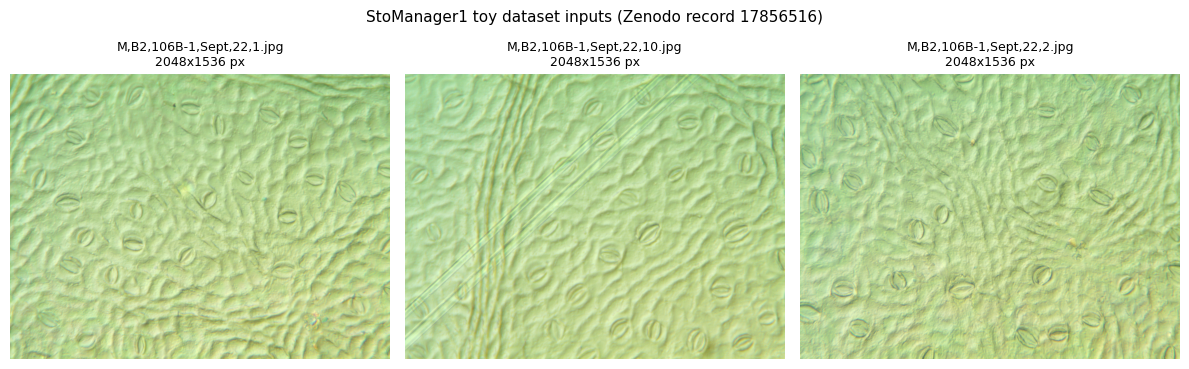

In [ ]:
import cv2
import matplotlib.pyplot as plt

input_files = sorted(os.listdir(INPUT_DIR))
imgs = [cv2.imread(os.path.join(INPUT_DIR, f)) for f in input_files]
fig, axes = plt.subplots(1, len(imgs), figsize=(4 * len(imgs), 4))
if len(imgs) == 1:
    axes = [axes]
for ax, im, name in zip(axes, imgs, input_files):
    ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{name}\n{im.shape[1]}x{im.shape[0]} px", fontsize=9)
    ax.axis("off")
fig.suptitle("StoManager1 toy dataset inputs (Zenodo record 17856516)", fontsize=11)
plt.tight_layout()
plt.show()


### 9. Run the author's CLI: `process` (YOLOv8x-seg inference)

Executes the pinned author code with the documented defaults (`-p 465`, `-c 0.25`, model `yolov8`) exactly as the README's CLI quick start shows. For every image the author code saves (a) a per-image metrics CSV under `output/Predict_output/Output_csv/` and (b) the annotated prediction image under `output/Predict_output/<name>/`. Runtime is measured; on CPU expect a few seconds per image, on GPU under a second.

**日本語:** 著者 CLI の `process`（YOLOv8x-seg 推論）を README 既定の引数で実行します。画像ごとの指標 CSV と注釈付き予測画像が出力されます。


In [ ]:
import glob
import time

t0 = time.time()
cmd = [sys.executable, "cli.py", "process", "-i", INPUT_DIR, "-o", OUT_DIR,
       "-m", "yolov8", "-p", "465", "-c", "0.25"]
proc = subprocess.run(cmd, cwd=CODE_DIR, text=True, capture_output=True)
print(proc.stdout[-3000:])
if proc.returncode != 0:
    print(proc.stderr[-3000:])
    raise RuntimeError(f"cli.py process failed with return code {proc.returncode}")
print(f"process finished in {time.time() - t0:.1f} s")

csv_dir = os.path.join(OUT_DIR, "Predict_output", "Output_csv")
csvs = sorted(f for f in os.listdir(csv_dir) if f.endswith(".csv"))
print("per-image CSVs:", csvs)



StoManager1 - Image Processing
Input folder: /content/stomanager_demo/input
Output folder: /content/stomanager_demo/output
Model: YOLOv8-seg-x
Pixel size: 465.0
Confidence: 0.25

WARNING ⚠️ 'line_thickness' is deprecated and will be removed in the future. Use 'line_width' instead.

0: 480x640 26 stomatas, 28 whole_stomatas, 5284.1ms
Speed: 15.5ms preprocess, 5284.1ms inference, 754.5ms postprocess per image at shape (1, 3, 480, 640)
Results saved to /content/stomanager_demo/output/Predict_output/Output_csv/M,B2,106B-1,Sept,22,1
1 label saved to /content/stomanager_demo/output/Predict_output/Output_csv/M,B2,106B-1,Sept,22,1/labels

Progress: |████████████████----------------------------------| 33%WARNING ⚠️ 'line_thickness' is deprecated and will be removed in the future. Use 'line_width' instead.

0: 480x640 30 stomatas, 30 whole_stomatas, 4903.4ms
Speed: 5.7ms preprocess, 4903.4ms inference, 468.3ms postprocess per image at shape (1, 3, 480, 640)
Results saved to /content/stomanager_

### 10. Inspect the per-image metric CSVs

Each CSV holds one row per matched whole-stomata/stomata pair with the paper's theoretical metrics: mask areas (µm², using the 465 px/0.1 mm calibration), lengths/widths from the minimum-area rotated rectangle, guard-cell dimensions, density, area ratios, and the SEve/SDiv/SAgg spatial indices (paper §2.4.2–2.4.3).

**日本語:** 画像ごとの CSV（マスク面積・ガードセル寸法・密度・空間指数など）の行数と先頭行を確認します。


In [ ]:
import pandas as pd

for csv_name in csvs:
    df = pd.read_csv(os.path.join(csv_dir, csv_name))
    print(f"{csv_name}: {df.shape[0]} matched pairs, {df.shape[1]} columns")
sample = pd.read_csv(os.path.join(csv_dir, csvs[0]))
cols = ["area_wst", "width_wst", "length_wst", "guardCell_length", "guardCell_width",
        "guardCell_area", "wst_density", "ratio_area_st_to_gc", "SEve", "SDiv", "SAgg"]
display(sample[cols].head(5))


M,B2,106B-1,Sept,22,1.csv: 16 matched pairs, 39 columns
M,B2,106B-1,Sept,22,10.csv: 21 matched pairs, 39 columns
M,B2,106B-1,Sept,22,2.csv: 20 matched pairs, 39 columns


,area_wst,width_wst,length_wst,guardCell_length,guardCell_width,guardCell_area,wst_density,ratio_area_st_to_gc,SEve,SDiv,SAgg
0,131,15,18,18.064516,3.440860,53,192,1.471698,0.5787,0.1062,1.3017
1,395,19,24,24.516129,4.086022,254,192,0.555118,0.5787,0.1062,1.3017
2,226,19,28,28.387097,5.161290,10,192,21.600000,0.5787,0.1062,1.3017
3,340,17,23,23.225806,4.301075,218,192,0.559633,0.5787,0.1062,1.3017
4,510,22,26,26.236559,3.440860,280,192,0.821429,0.5787,0.1062,1.3017


### 11. Run the author's CLI: `stats` (summary workbook)

`python cli.py stats -o <out> -m yolov8` aggregates all per-image CSVs into a single `Stomata_output_*.xlsx` (one row per image, outlier-trimmed mean/median/min/max per metric — the author's `StatisticsCalculator`). We print the workbook path and show a compact selection of the summary columns.

**日本語:** 著者 CLI の `stats` を実行し、画像ごとの集計（外れ値除去後の mean/median/min/max）を含む XLSX を生成して主要列を表示します。


In [ ]:
t0 = time.time()
proc = subprocess.run([sys.executable, "cli.py", "stats", "-o", OUT_DIR, "-m", "yolov8"],
                      cwd=CODE_DIR, text=True, capture_output=True)
print(proc.stdout[-1500:])
if proc.returncode != 0:
    print(proc.stderr[-2000:])
    raise RuntimeError(f"cli.py stats failed with return code {proc.returncode}")
print(f"stats finished in {time.time() - t0:.1f} s")

xlsx_files = sorted(glob.glob(os.path.join(csv_dir, "Stomata_output_*.xlsx")))
assert xlsx_files, "stats produced no workbook"
xlsx_path = xlsx_files[-1]
stats_df = pd.read_excel(xlsx_path)
print("workbook:", os.path.basename(xlsx_path), "| rows:", stats_df.shape[0], "| columns:", stats_df.shape[1])
show_cols = ["Filename", "No_wst_median", "area_wst_median", "length_wst_median", "width_wst_median",
             "guardCell_length_median", "guardCell_width_median", "guardCell_area_median",
             "wst_density_mean", "SEve_mean", "SDiv_mean", "SAgg_mean"]
show_cols = [c for c in show_cols if c in stats_df.columns]
display(stats_df[show_cols])



StoManager1 - Statistical Analysis
Output folder: /content/stomanager_demo/output
Model: YOLOv8-seg-x
Group analysis: False


Progress: |████████████████----------------------------------| 33%
Progress: |█████████████████████████████████-----------------| 66%
Progress: |██████████████████████████████████████████████████| 100%

✓ Statistical analysis complete!
Statistics saved to: /content/stomanager_demo/output/Predict_output/Output_csv/Stomata_output_SCOF.xlsx

stats finished in 4.4 s


workbook: Stomata_output_SCOF.xlsx | rows: 3 | columns: 125


,Filename,No_wst_median,area_wst_median,length_wst_median,width_wst_median,guardCell_length_median,guardCell_width_median,guardCell_area_median,wst_density_mean,SEve_mean,SDiv_mean,SAgg_mean
0,"M,B2,106B-1,Sept,22,10",29,356,23,18,23,4,215,199,0.5344,0.0925,1.4826
1,"M,B2,106B-1,Sept,22,2",30,314,21,18,22,4,182,206,0.5376,0.1145,1.5355
2,"M,B2,106B-1,Sept,22,1",28,176,20,17,21,4,28,192,0.5787,0.1062,1.3017


### 12. Input vs. StoManager1 prediction overlay

Side-by-side view of each original micrograph and the annotation image the author code saved during `process` (ultralytics mask overlay; label colors distinguish the two classes). This is the executed result of this reproduction — the same overlay the GUI shows in the paper's Figure-style workflow. The figure is saved as a PNG artifact of this run.

**日本語:** 入力画像と、著者コードが `process` 中に保存した予測オーバーレイを並べて表示します（この再現の実行結果そのものです）。


prediction images: ['Output_csv/M,B2,106B-1,Sept,22,1/image0.jpg', 'Output_csv/M,B2,106B-1,Sept,22,10/image0.jpg', 'Output_csv/M,B2,106B-1,Sept,22,2/image0.jpg']


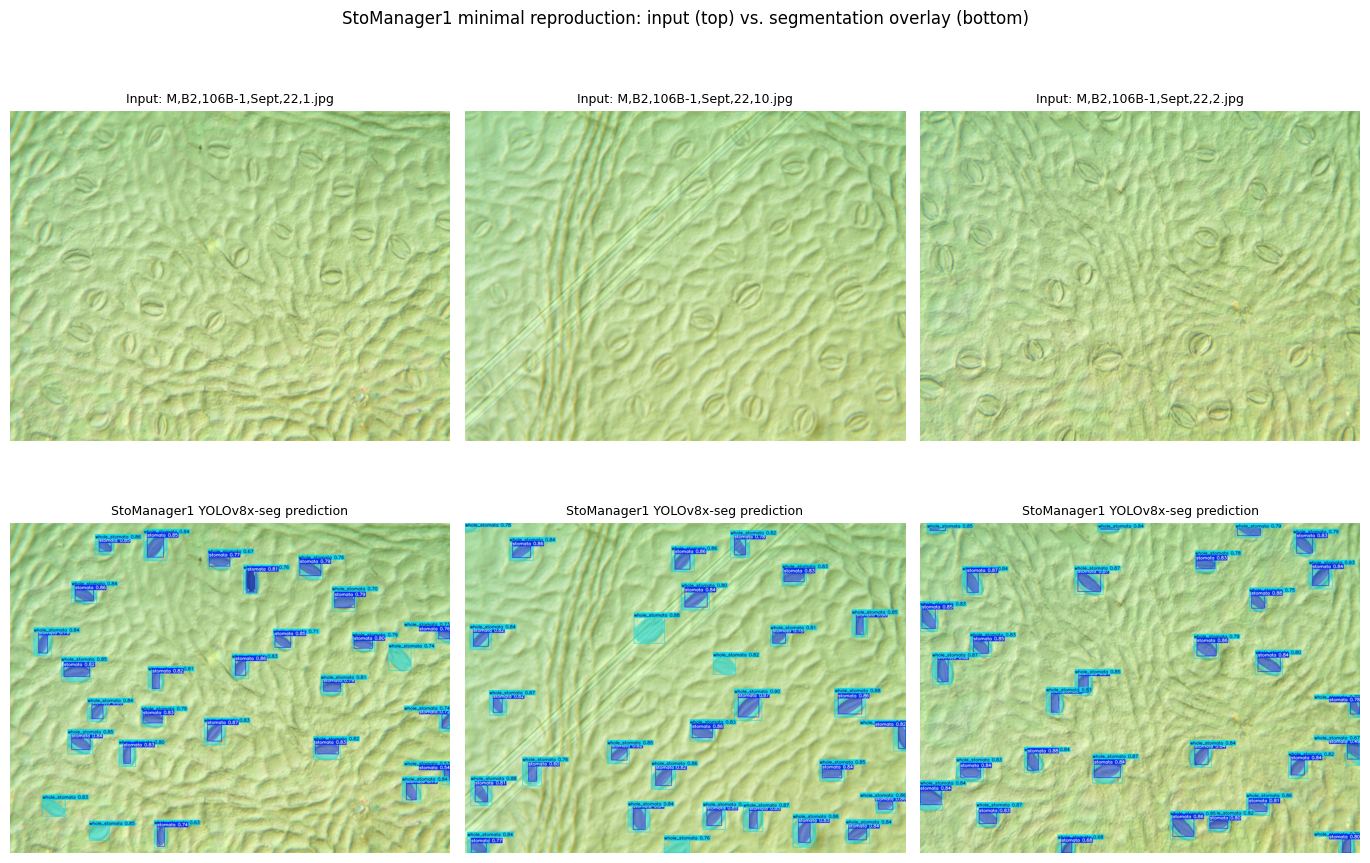

saved: /content/stomanager_demo/input_vs_prediction.png


In [ ]:
import matplotlib.image as mpimg

pred_dir = os.path.join(OUT_DIR, "Predict_output")
overlay_files = []
for root, dirs, fs in os.walk(pred_dir):
    for name in sorted(fs):
        if name.lower().endswith((".jpg", ".png")):
            overlay_files.append(os.path.join(root, name))
overlay_files = sorted(overlay_files)
assert overlay_files, "no prediction images saved by the author code"
print("prediction images:", [os.path.relpath(p, pred_dir) for p in overlay_files])

n_show = min(3, len(overlay_files))
fig, axes = plt.subplots(2, n_show, figsize=(4.6 * n_show, 9.5))
for i in range(n_show):
    inp = cv2.cvtColor(cv2.imread(os.path.join(INPUT_DIR, input_files[i])), cv2.COLOR_BGR2RGB)
    ovl = cv2.cvtColor(cv2.imread(overlay_files[i]), cv2.COLOR_BGR2RGB)
    axes[0, i].imshow(inp); axes[0, i].set_title(f"Input: {input_files[i]}", fontsize=9)
    axes[1, i].imshow(ovl); axes[1, i].set_title("StoManager1 YOLOv8x-seg prediction", fontsize=9)
    for ax in (axes[0, i], axes[1, i]):
        ax.axis("off")
fig.suptitle("StoManager1 minimal reproduction: input (top) vs. segmentation overlay (bottom)", fontsize=12)
plt.tight_layout()
plt.savefig(os.path.join(DEMO, "input_vs_prediction.png"), dpi=110, bbox_inches="tight")
plt.show()
print("saved:", os.path.join(DEMO, "input_vs_prediction.png"))


## Interpretation and limitations

**What this example shows.** The author's released YOLOv8x-seg checkpoint detects and segments the two stomata classes in the toy micrographs, and the author's geometry code converts the masks into the paper's theoretical metrics (µm² areas via the Surveyor's formula, length/width/orientation via the minimum rotated rectangle, guard-cell dimensions by subtracting the pore mask from the whole-stomata mask, plus density, ratios and the SEve/SDiv/SAgg indices), matching paper §2.4.2–2.4.3 and Table 2 metric families.

**What it does not show.** A 3-image run cannot verify the paper's reported segmentation mAP@0.5 > 0.994, the measurement error tables, or the biological correlations (§3.2–3.4); those need the full labeled datasets and validation sets. The `pixel_size = 465` default is the author's CLI default — the calibration of these toy images was not stated in the README, so absolute µm² values inherit that assumption. The YOLOv3 empirical-regression path and the Windows GUI are not exercised.

**この例で分かること・分からないこと（日本語）:** 公開済み重みによる検出・セグメンテーションと、マスクから 30+ 指標を計算する著者の幾何処理が Colab で再現できます。ただし少数例では論文の精度・生体相関の検証はできません。較正値 465 px/0.1mm は著者既定値の仮定です。

**Validation record:** this notebook was executed top-to-bottom on fresh Colab runtimes (CPU and T4); hardware, versions, timings and the MD5 checks are visible in the saved outputs above.


## References and provenance

- Wang, J., Renninger, H. J., & Ma, Q. *StoManager1: An Enhanced, Automated, and High-throughput Tool to Measure Leaf Stomata and Guard Cell Metrics…* arXiv:2304.10450v3; *Plant Physiology* (2024) kiae049.
- Author code: https://github.com/JiaxinWang123/StoManager1 @ `9974130ec64b5a04528177f93a67cb825670e397` (files: `cli.py`, `config/constants.py`, `processors/yolov8_processor.py`, `processors/stomata_analyzer.py`, `stats/calculator.py`).
- Trained weights & toy data: Zenodo record 17856516 (`YOLOV8x_weights.zip`, `Toy dataset.rar`; MD5s verified in-notebook). Same deposit as DOI 10.5281/zenodo.10553682 (v1.0.0).
- Datasets paper: Wang et al., *Sci Data* 11 (2024), doi:10.1038/s41597-023-02657-3.
- PhenoPaper investigation `p-32e9a302d0d1f027bfc60b4b48d812f4-20261026T173549Z-1668501` was used as prior research guidance; all executable claims above were re-verified against the pinned author code.
